# 1. Работа с изображениями

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from imageio import imread

C:\Users\D\AppData\Local\Temp\ipykernel_11016\240973613.py:2: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  img_rgb = imread(image_link)


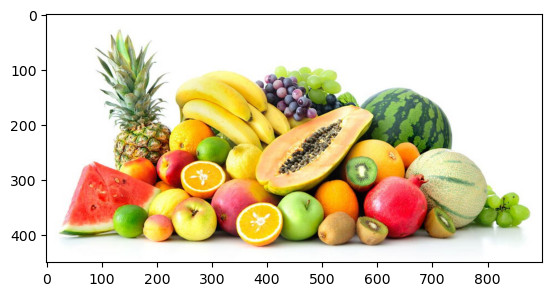

In [2]:
image_link = r"C:\Courses\Innopolis\2026\ИИ Инженер\Data\Pictures\fruit-og-z8vk4201s653efw.jpg"
img_rgb = imread(image_link)
plt.imshow(img_rgb)
plt.show()

In [12]:
type(img_rgb)

numpy.ndarray

In [3]:
img_rgb.shape

(450, 900, 3)

In [14]:
np.prod(img_rgb.shape)

np.int64(1215000)

In [13]:
img_rgb[275:280, 600:605, :].transpose(2, 0 ,1)

array([[[215, 242, 250, 244, 247],
        [185, 226, 243, 242, 249],
        [163, 216, 241, 247, 255],
        [153, 208, 240, 254, 255],
        [146, 203, 237, 254, 255]],

       [[187, 194, 191, 179, 181],
        [172, 188, 185, 171, 175],
        [164, 185, 183, 169, 173],
        [162, 183, 179, 167, 173],
        [159, 180, 174, 163, 169]],

       [[ 90,  84,  63,  37,  32],
        [ 76,  81,  60,  31,  28],
        [ 70,  79,  60,  33,  31],
        [ 69,  80,  62,  36,  34],
        [ 67,  76,  58,  33,  32]]], dtype=uint8)

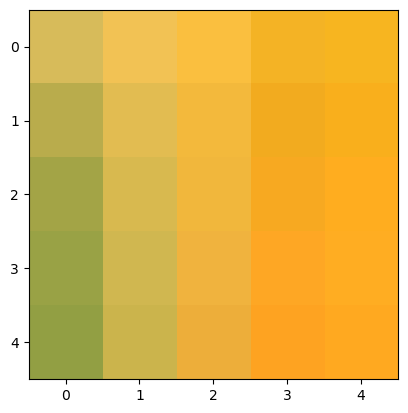

In [8]:
plt.imshow(img_rgb[275:280, 600:605, :])
plt.show()

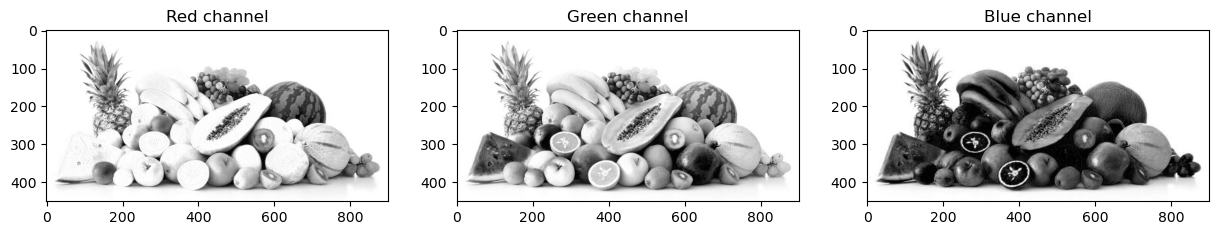

In [16]:
index_to_channel = {
    0: "Red channel",
    1: "Green channel",
    2: "Blue channel"
}

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
for i in range(3):
    ax[i].imshow(img_rgb[:, :, i], cmap="gray")
    ax[i].set_title(index_to_channel[i])
plt.show()

# 2. Примеры применения фильтров

In [19]:
import cv2
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from imageio import imread

from scipy.signal import convolve2d, medfilt2d
from scipy.ndimage import median_filter

In [20]:
# Напишем функцию для отображения исходной и новой картинки

def plot_images(img_1, img_2, title_1, title_2, sup_title):
  fig, ax = plt.subplots(1, 2, figsize=(15, 5))
  plt.suptitle(sup_title)
  ax[0].imshow(img_1, cmap="gray")
  ax[0].set_title(title_1)
  ax[1].imshow(img_2, cmap="gray")
  ax[1].set_title(title_2)
  plt.show()

  print("Размер исходного изображения: ", img_1.shape)
  print("Размер нового  изображения: ", img_2.shape)

# Напишем функцию для создания свертки
def get_convolution(img, kernel):
  return convolve2d(img, kernel, mode = 'same')

# Напишем обобщающую функцию для отображения всей картинки и небольшого сэмпла
def inspect_convolution(img, kernel, title_1, title_2):
  conv_img = get_convolution(img, kernel)
  plot_images(img, conv_img, title_1, title_2, "Целое изображение")
  print("\n")
  plot_images(img[345:355, 130:140], conv_img[345:355, 130:140], title_1, title_2, "Сэмпл изображения")
  print("\n")
  print("Матрица исходного сэмпла: \n", img[345:355, 130:140])
  print("\n")
  print("Матрица сверточного сэмпла: \n", np.round(conv_img[345:355, 130:140], 2))

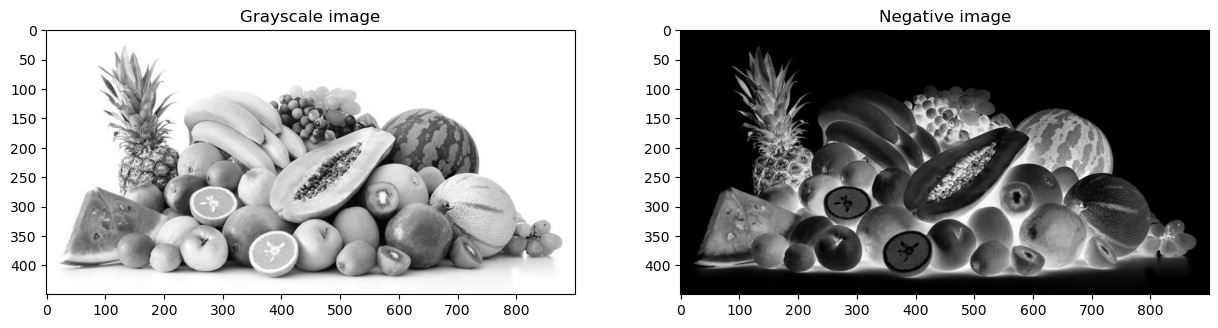

Размер исходного изображения:  (450, 900)
Размер нового  изображения:  (450, 900)


In [21]:
# Конвертируем изображение в Grayscale
img_gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
img_negative = img_gray.max() - img_gray

plot_images(img_gray, img_negative, "Grayscale image", "Negative image", "")

## 2.1. Identity kernel

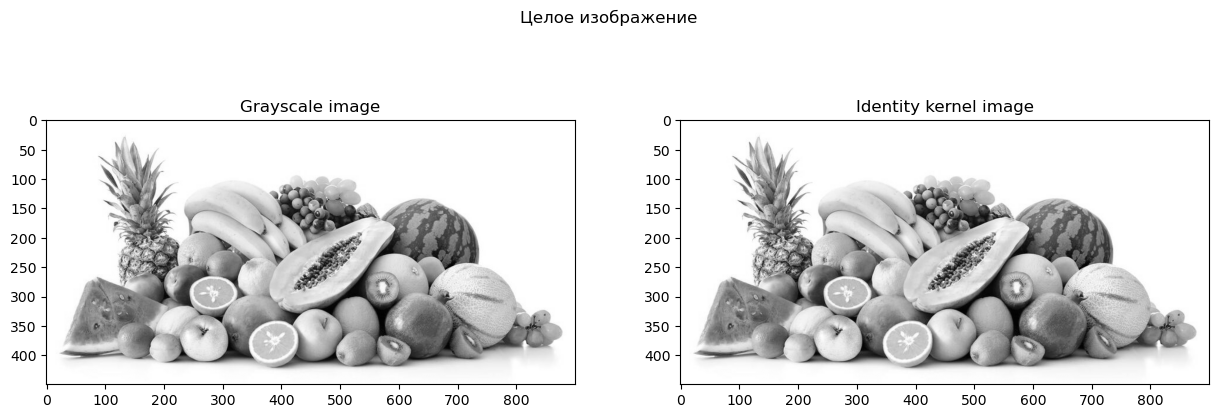

Размер исходного изображения:  (450, 900)
Размер нового  изображения:  (450, 900)




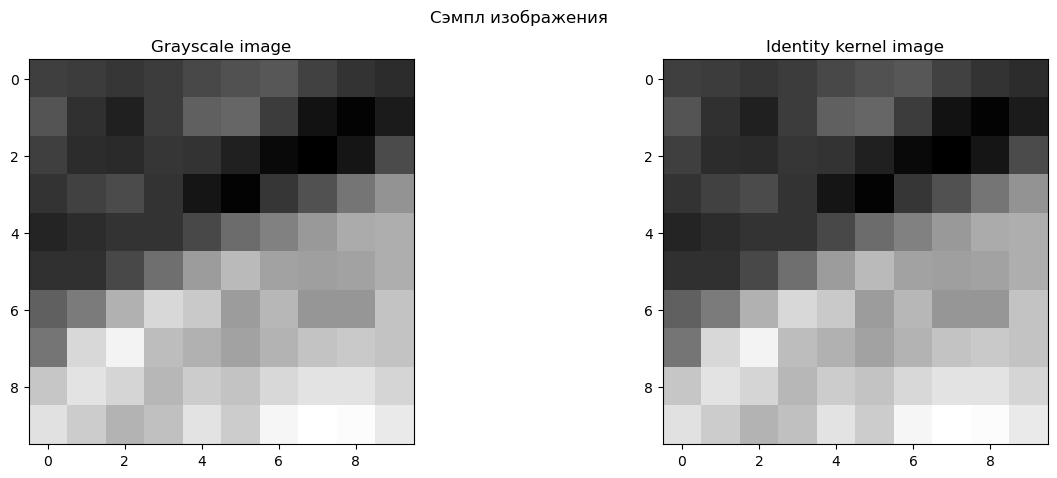

Размер исходного изображения:  (10, 10)
Размер нового  изображения:  (10, 10)


Матрица исходного сэмпла: 
 [[111 110 108 110 114 117 119 112 107 105]
 [118 106 101 110 122 124 110  96  91  99]
 [111 105 104 108 107 101  93  90  97 115]
 [107 112 115 107  97  91 108 117 129 139]
 [102 105 107 107 114 126 133 141 147 148]
 [106 106 114 127 142 152 144 143 144 148]
 [122 131 149 162 157 142 151 140 140 155]
 [129 162 171 153 149 144 150 155 157 155]
 [156 166 161 151 158 155 162 166 166 161]
 [165 158 150 154 166 158 172 175 174 168]]


Матрица сверточного сэмпла: 
 [[111 110 108 110 114 117 119 112 107 105]
 [118 106 101 110 122 124 110  96  91  99]
 [111 105 104 108 107 101  93  90  97 115]
 [107 112 115 107  97  91 108 117 129 139]
 [102 105 107 107 114 126 133 141 147 148]
 [106 106 114 127 142 152 144 143 144 148]
 [122 131 149 162 157 142 151 140 140 155]
 [129 162 171 153 149 144 150 155 157 155]
 [156 166 161 151 158 155 162 166 166 161]
 [165 158 150 154 166 158 172 175 174 168]

In [22]:
identity_kernel = np.array([[0, 0, 0],
                            [0, 1, 0],
                            [0, 0, 0]])

inspect_convolution(img_gray, identity_kernel, "Grayscale image", "Identity kernel image")

## 2.2. Box blur / Average

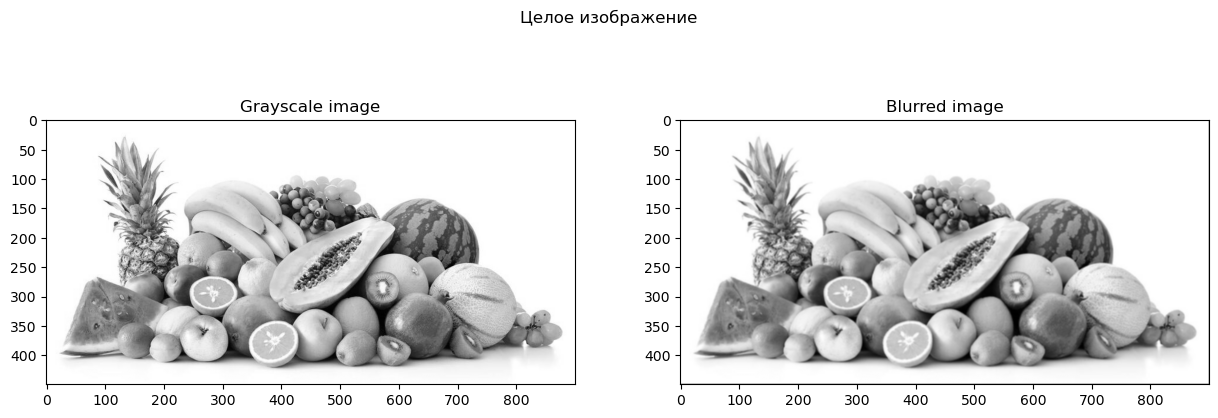

Размер исходного изображения:  (450, 900)
Размер нового  изображения:  (450, 900)




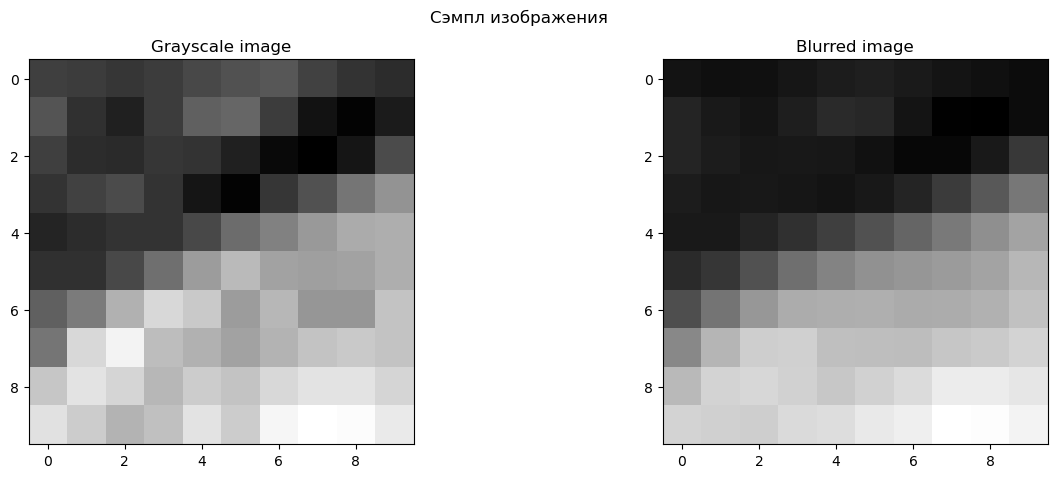

Размер исходного изображения:  (10, 10)
Размер нового  изображения:  (10, 10)


Матрица исходного сэмпла: 
 [[111 110 108 110 114 117 119 112 107 105]
 [118 106 101 110 122 124 110  96  91  99]
 [111 105 104 108 107 101  93  90  97 115]
 [107 112 115 107  97  91 108 117 129 139]
 [102 105 107 107 114 126 133 141 147 148]
 [106 106 114 127 142 152 144 143 144 148]
 [122 131 149 162 157 142 151 140 140 155]
 [129 162 171 153 149 144 150 155 157 155]
 [156 166 161 151 158 155 162 166 166 161]
 [165 158 150 154 166 158 172 175 174 168]]


Матрица сверточного сэмпла: 
 [[106.44 105.56 105.78 107.33 109.   109.67 108.33 106.67 105.67 104.67]
 [111.11 108.22 106.89 109.33 112.56 111.89 106.89 101.67 101.33 104.56]
 [111.22 108.78 107.56 107.89 107.44 105.89 103.33 103.44 108.11 116.22]
 [108.78 107.56 107.78 107.33 106.44 107.78 111.11 117.22 124.78 133.11]
 [108.22 108.22 111.11 114.44 118.11 123.   128.33 134.   139.56 144.89]
 [112.56 115.78 123.11 131.   136.56 140.11 141.33 142.56 145.11

In [23]:
blur_kernel = np.ones((3,3)) / 9

inspect_convolution(img_gray, blur_kernel, "Grayscale image", "Blurred image")

## 2.3. Gaussian Blur kernel

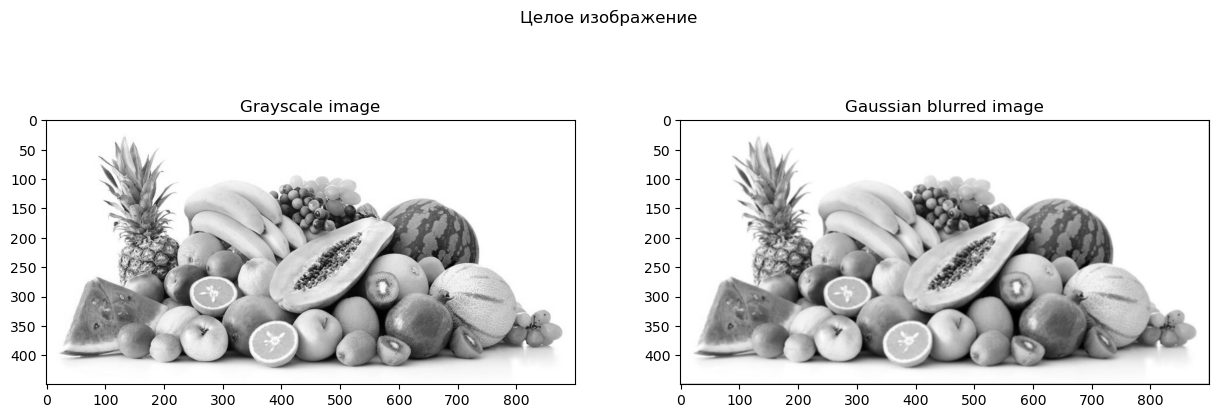

Размер исходного изображения:  (450, 900)
Размер нового  изображения:  (450, 900)




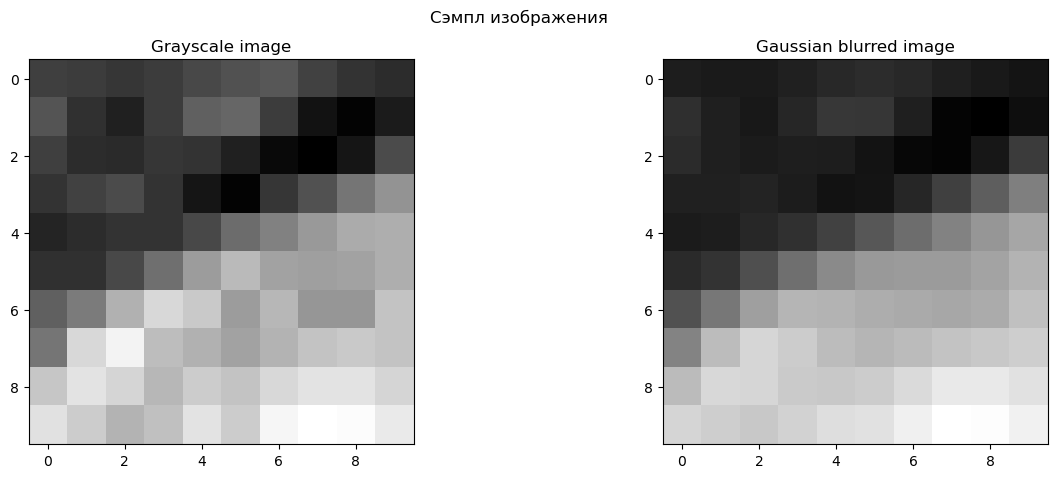

Размер исходного изображения:  (10, 10)
Размер нового  изображения:  (10, 10)


Матрица исходного сэмпла: 
 [[111 110 108 110 114 117 119 112 107 105]
 [118 106 101 110 122 124 110  96  91  99]
 [111 105 104 108 107 101  93  90  97 115]
 [107 112 115 107  97  91 108 117 129 139]
 [102 105 107 107 114 126 133 141 147 148]
 [106 106 114 127 142 152 144 143 144 148]
 [122 131 149 162 157 142 151 140 140 155]
 [129 162 171 153 149 144 150 155 157 155]
 [156 166 161 151 158 155 162 166 166 161]
 [165 158 150 154 166 158 172 175 174 168]]


Матрица сверточного сэмпла: 
 [[107.38 106.5  106.44 108.12 110.31 111.5  110.62 107.94 106.06 104.75]
 [112.38 107.88 105.81 109.69 114.62 114.31 107.75 100.38  99.   103.19]
 [111.19 107.94 106.81 107.69 107.25 104.44 101.12 100.25 105.56 115.81]
 [108.5  108.5  109.06 107.12 104.25 104.69 109.88 117.12 125.62 134.62]
 [106.81 107.25 110.12 112.88 117.31 123.44 129.56 135.56 141.19 145.69]
 [110.94 113.5  121.19 130.31 137.81 141.94 142.69 142.56 144.75

In [24]:
gauss_kernel = np.array([[1, 2, 1],
                         [2, 4, 2],
                         [1, 2, 1]])
gauss_kernel = gauss_kernel / gauss_kernel.sum()

inspect_convolution(img_gray, gauss_kernel, "Grayscale image", "Gaussian blurred image")

## 2.4. Sharpen kernel

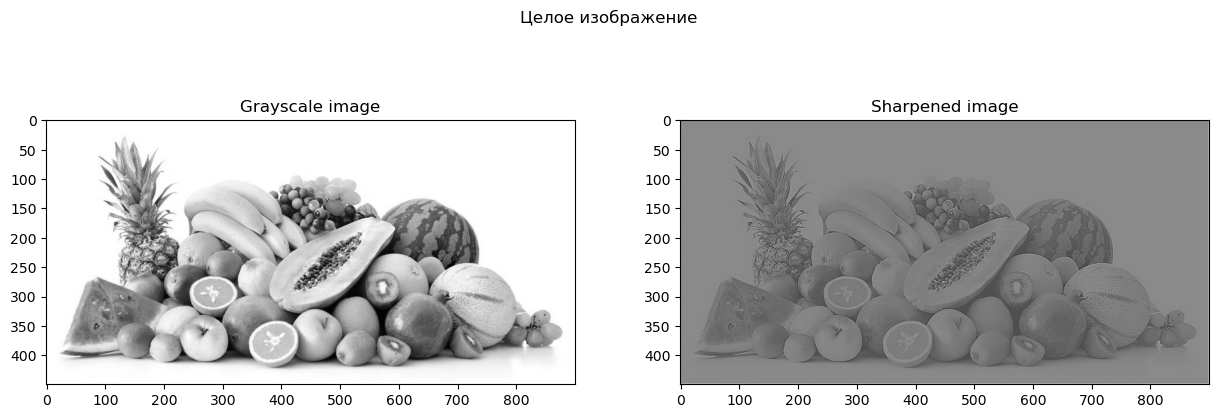

Размер исходного изображения:  (450, 900)
Размер нового  изображения:  (450, 900)




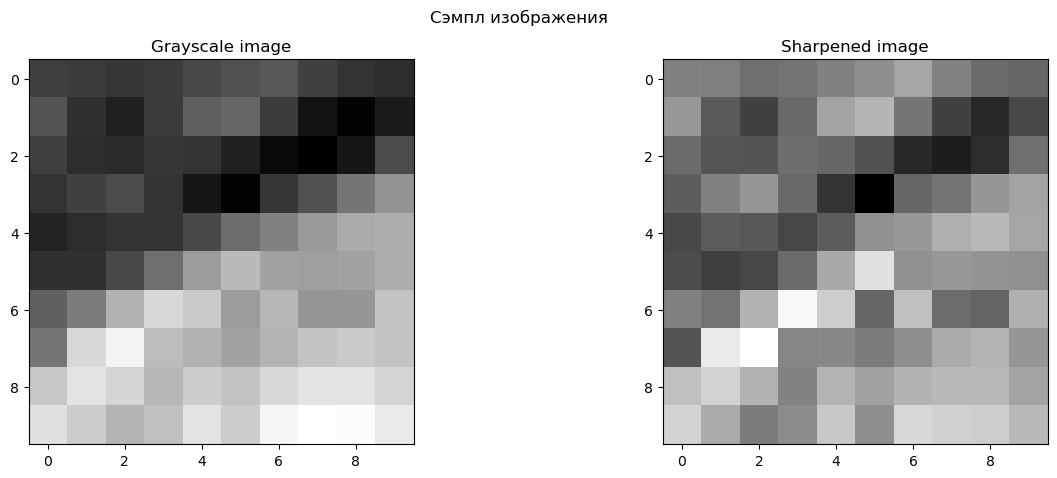

Размер исходного изображения:  (10, 10)
Размер нового  изображения:  (10, 10)


Матрица исходного сэмпла: 
 [[111 110 108 110 114 117 119 112 107 105]
 [118 106 101 110 122 124 110  96  91  99]
 [111 105 104 108 107 101  93  90  97 115]
 [107 112 115 107  97  91 108 117 129 139]
 [102 105 107 107 114 126 133 141 147 148]
 [106 106 114 127 142 152 144 143 144 148]
 [122 131 149 162 157 142 151 140 140 155]
 [129 162 171 153 149 144 150 155 157 155]
 [156 166 161 151 158 155 162 166 166 161]
 [165 158 150 154 166 158 172 175 174 168]]


Матрица сверточного сэмпла: 
 [[128 126 113 116 128 139 157 129 110 106]
 [146  96  77 109 155 170 118  77  56  82]
 [110  92  91 112 107  90  56  47  60 113]
 [ 99 128 145 108  66  23 106 117 145 156]
 [ 81  98  94  80  98 140 146 165 173 157]
 [ 86  74  81 110 160 206 141 146 142 140]
 [128 116 167 224 190 106 179 111 104 166]
 [ 91 213 230 132 133 124 138 162 169 145]
 [178 193 167 129 169 153 167 172 172 156]
 [194 162 124 137 185 139 198 192 190 173]

In [25]:
sharpen_kernel = np.array([[0, -1, 0],
                            [-1, 5, -1],
                            [0, -1, 0]])

inspect_convolution(img_gray, sharpen_kernel, "Grayscale image", "Sharpened image")

## 2.5. Sobel filters (horizontal)

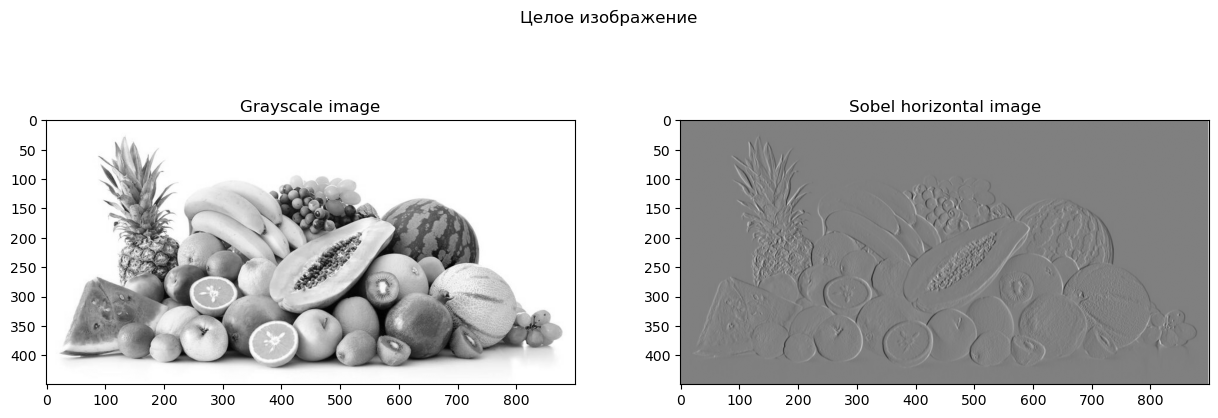

Размер исходного изображения:  (450, 900)
Размер нового  изображения:  (450, 900)




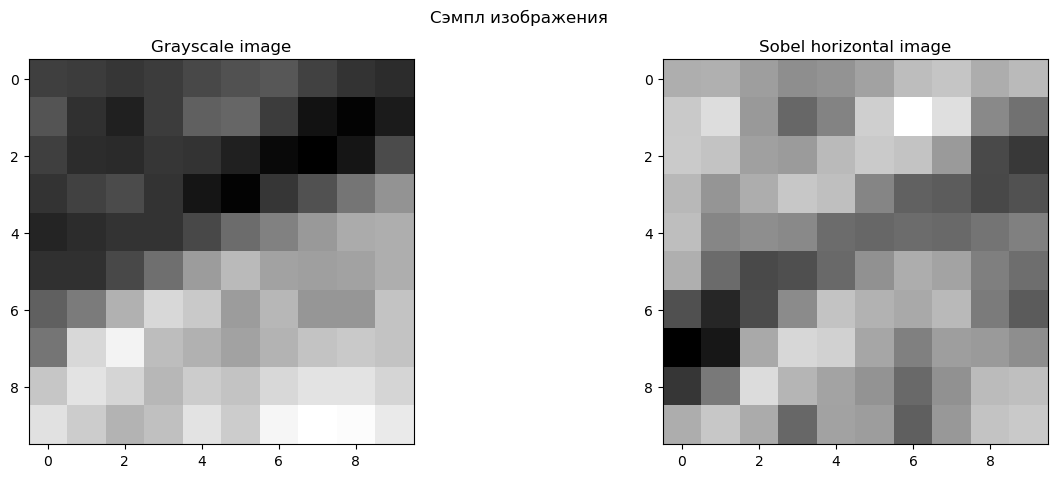

Размер исходного изображения:  (10, 10)
Размер нового  изображения:  (10, 10)


Матрица исходного сэмпла: 
 [[111 110 108 110 114 117 119 112 107 105]
 [118 106 101 110 122 124 110  96  91  99]
 [111 105 104 108 107 101  93  90  97 115]
 [107 112 115 107  97  91 108 117 129 139]
 [102 105 107 107 114 126 133 141 147 148]
 [106 106 114 127 142 152 144 143 144 148]
 [122 131 149 162 157 142 151 140 140 155]
 [129 162 171 153 149 144 150 155 157 155]
 [156 166 161 151 158 155 162 166 166 161]
 [165 158 150 154 166 158 172 175 174 168]]


Матрица сверточного сэмпла: 
 [[   6    8   -7  -20  -15   -4   18   25    5   16]
 [  28   44  -11  -51  -28   33   72   46  -24  -43]
 [  29   23   -5   -9   16   29   24  -10  -75  -89]
 [  14  -14    5   26   20  -27  -56  -60  -76  -68]
 [  19  -26  -20  -24  -47  -51  -47  -49  -41  -31]
 [   7  -48  -75  -71  -49  -17    5   -3  -32  -46]
 [ -70 -104  -74  -22   24    9    2   15  -35  -61]
 [-135 -116    2   39   34    0  -31   -7  -10  -20]
 [ -9

In [26]:
sobel_h_kernel = np.array([[-1, 0, 1],
                            [-2, 0, 2],
                            [-1, 0, 1]])

inspect_convolution(img_gray, sobel_h_kernel, "Grayscale image", "Sobel horizontal image")

## 2.6. Sobel vertical filter

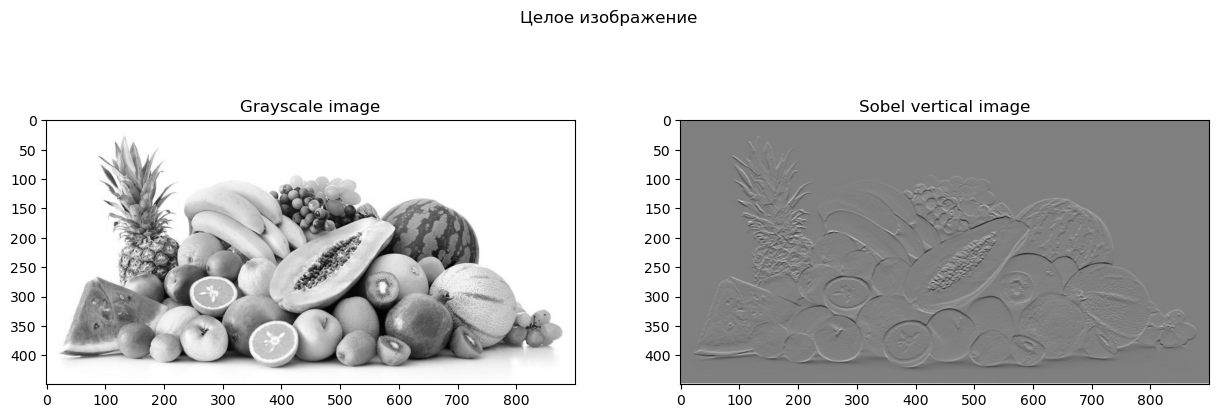

Размер исходного изображения:  (450, 900)
Размер нового  изображения:  (450, 900)




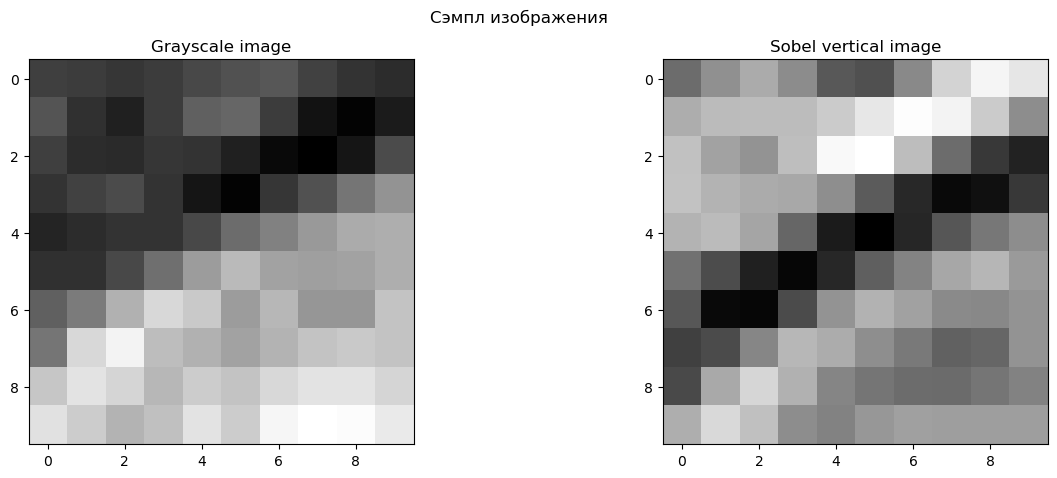

Размер исходного изображения:  (10, 10)
Размер нового  изображения:  (10, 10)


Матрица исходного сэмпла: 
 [[111 110 108 110 114 117 119 112 107 105]
 [118 106 101 110 122 124 110  96  91  99]
 [111 105 104 108 107 101  93  90  97 115]
 [107 112 115 107  97  91 108 117 129 139]
 [102 105 107 107 114 126 133 141 147 148]
 [106 106 114 127 142 152 144 143 144 148]
 [122 131 149 162 157 142 151 140 140 155]
 [129 162 171 153 149 144 150 155 157 155]
 [156 166 161 151 158 155 162 166 166 161]
 [165 158 150 154 166 158 172 175 174 168]]


Матрица сверточного сэмпла: 
 [[ -78  -36   -5  -40 -101 -110  -44   41   81   64]
 [  -2   14   15   15   32   65   90   80   32  -39]
 [  21  -15  -31   17   86   93   16  -78 -137 -163]
 [  22    6   -5   -8  -38  -97 -156 -192 -184 -138]
 [   5   14  -12  -84 -171 -203 -159 -103  -65  -39]
 [ -71 -114 -165 -195 -157  -93  -51   -9    8  -24]
 [-102 -192 -196 -116  -32    3  -16  -43  -45  -31]
 [-129 -116  -48    9   -4  -38  -61  -89  -84  -32]
 [-11

In [27]:
sobel_v_kernel = np.array([[-1, -2, -1],
                            [0, 0, 0],
                            [1, 2, 1]])


inspect_convolution(img_gray, sobel_v_kernel, "Grayscale image", "Sobel vertical image")

## 2.7. Laplacian filter

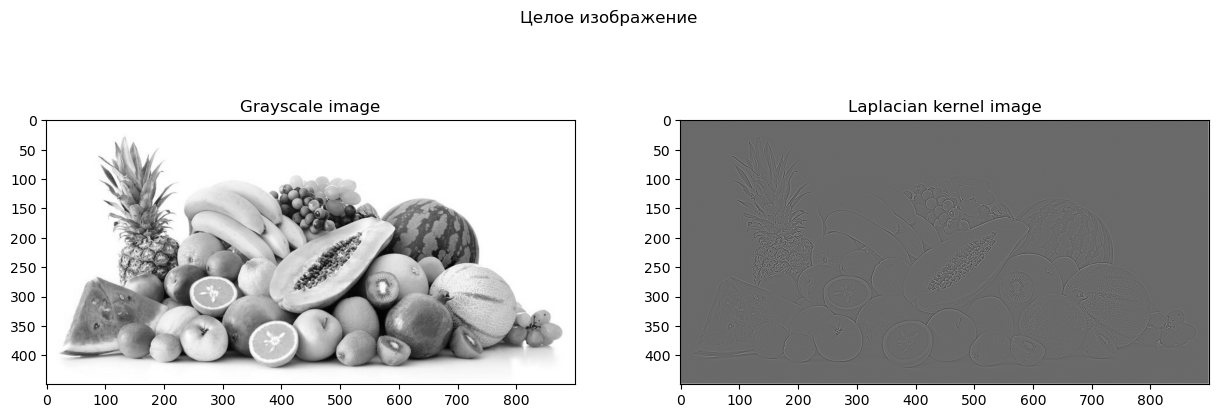

Размер исходного изображения:  (450, 900)
Размер нового  изображения:  (450, 900)




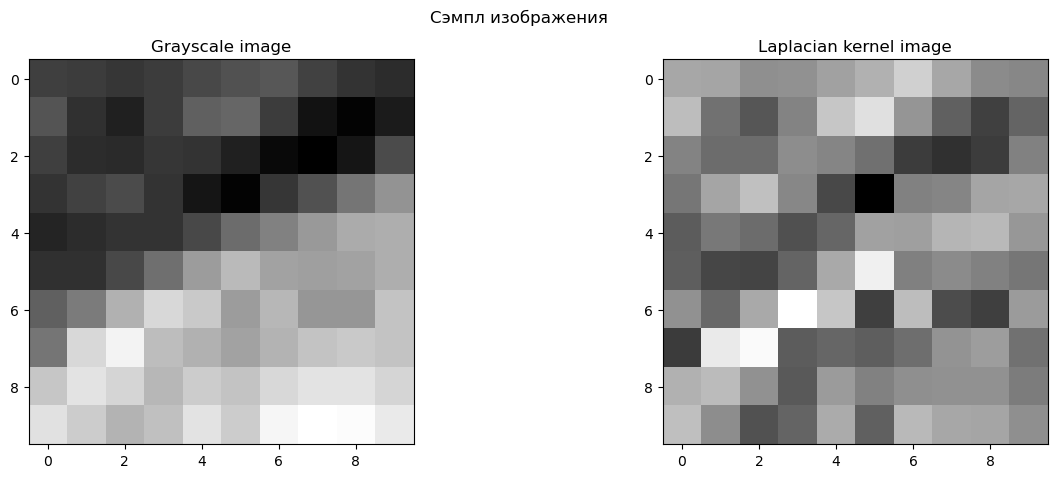

Размер исходного изображения:  (10, 10)
Размер нового  изображения:  (10, 10)


Матрица исходного сэмпла: 
 [[111 110 108 110 114 117 119 112 107 105]
 [118 106 101 110 122 124 110  96  91  99]
 [111 105 104 108 107 101  93  90  97 115]
 [107 112 115 107  97  91 108 117 129 139]
 [102 105 107 107 114 126 133 141 147 148]
 [106 106 114 127 142 152 144 143 144 148]
 [122 131 149 162 157 142 151 140 140 155]
 [129 162 171 153 149 144 150 155 157 155]
 [156 166 161 151 158 155 162 166 166 161]
 [165 158 150 154 166 158 172 175 174 168]]


Матрица сверточного сэмпла: 
 [[ 17  16   5   6  14  22  38  17   3   1]
 [ 28 -10 -24  -1  33  46   8 -19 -35 -17]
 [ -1 -13 -13   4   0 -11 -37 -43 -37  -2]
 [ -8  16  30   1 -31 -68  -2   0  16  17]
 [-21  -7 -13 -27 -16  14  13  24  26   9]
 [-20 -32 -33 -17  18  54  -3   3  -2  -8]
 [  6 -15  18  62  33 -36  28 -29 -36  11]
 [-38  51  59 -21 -16 -20 -12   7  12 -10]
 [ 22  27   6 -22  11  -2   5   6   6  -5]
 [ 29   4 -26 -17  19 -19  26  17  16   5]

In [28]:
laplacian_kernel = np.array([[0, -1, 0],
                            [-1, 4, -1],
                            [0, -1, 0]])

inspect_convolution(img_gray, laplacian_kernel, "Grayscale image", "Laplacian kernel image")

## 2.8. Emboss filter

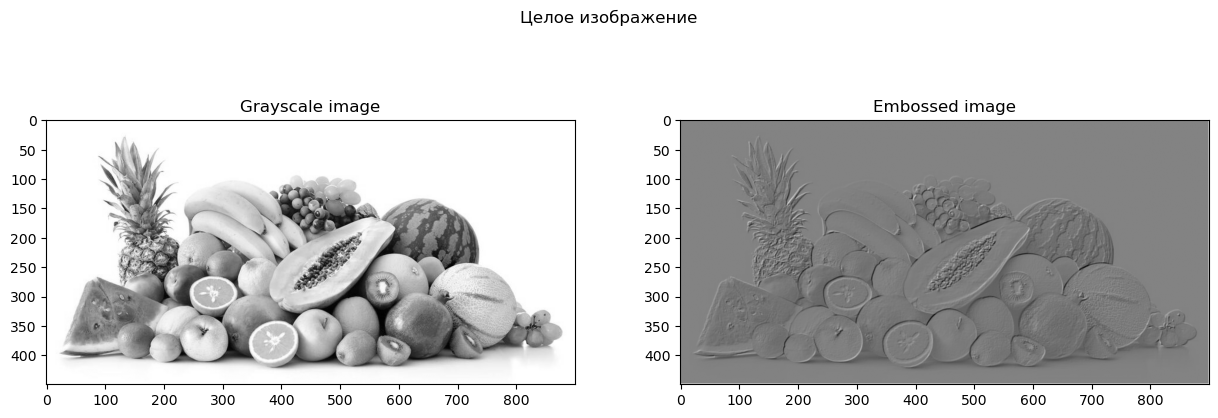

Размер исходного изображения:  (450, 900)
Размер нового  изображения:  (450, 900)




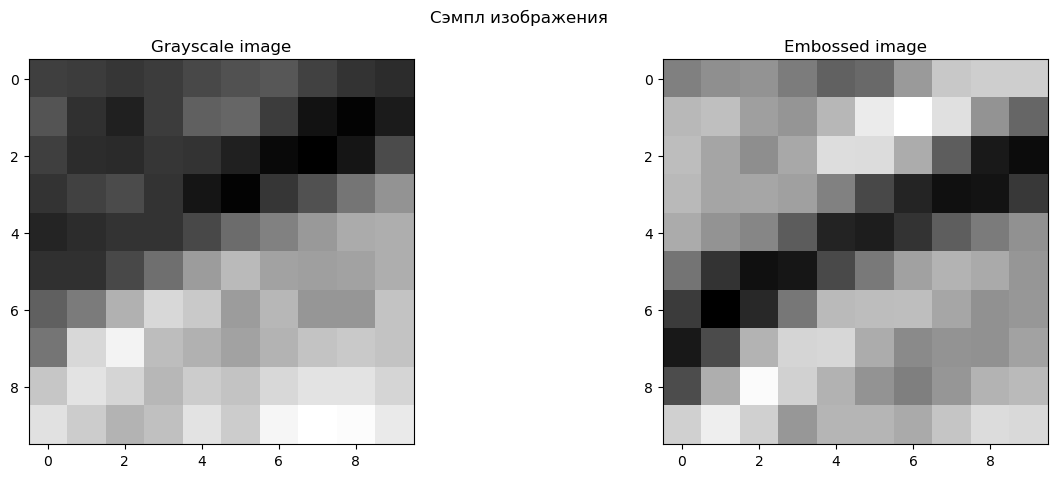

Размер исходного изображения:  (10, 10)
Размер нового  изображения:  (10, 10)


Матрица исходного сэмпла: 
 [[111 110 108 110 114 117 119 112 107 105]
 [118 106 101 110 122 124 110  96  91  99]
 [111 105 104 108 107 101  93  90  97 115]
 [107 112 115 107  97  91 108 117 129 139]
 [102 105 107 107 114 126 133 141 147 148]
 [106 106 114 127 142 152 144 143 144 148]
 [122 131 149 162 157 142 151 140 140 155]
 [129 162 171 153 149 144 150 155 157 155]
 [156 166 161 151 158 155 162 166 166 161]
 [165 158 150 154 166 158 172 175 174 168]]


Матрица сверточного сэмпла: 
 [[ 68  86  91  64  34  43  99 153 160 160]
 [134 142 105  93 133 194 218 181  92  38]
 [140 112  85 116 177 176 120  27 -52 -67]
 [135 112 113 106  70   3 -38 -63 -59 -16]
 [119  92  76  26 -40 -48 -22  29  63  89]
 [ 54 -22 -63 -56   4  60 107 130 118  94]
 [-12 -82 -33  58 136 140 141 113  88  96]
 [-53   7 128 168 171 120  80  92  89 109]
 [  8 123 213 163 127  91  67  94 128 136]
 [162 198 162  95 131 131 118 150 176 173]

In [29]:
emboss_kernel = np.array([[-2, -1, 0],
                          [-1, 1, 1],
                          [0, 1, 2]])

inspect_convolution(img_gray, emboss_kernel, "Grayscale image", "Embossed image")

## 2.9. Обученные свертки в нейросетях

Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to C:\Users\D/.cache\torch\hub\checkpoints\vgg16-397923af.pth


100%|██████████| 528M/528M [02:37<00:00, 3.52MB/s] 


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\Users\D/.cache\torch\hub\checkpoints\resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:05<00:00, 8.60MB/s]


VGG first layer shape: torch.Size([64, 3, 3, 3])
ResNet first layer shape: torch.Size([64, 3, 7, 7])


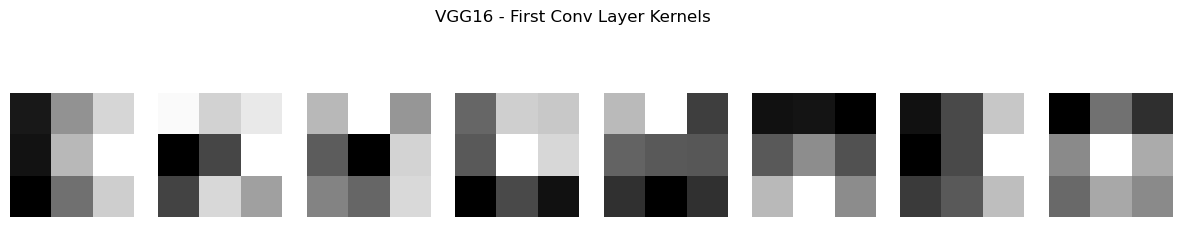

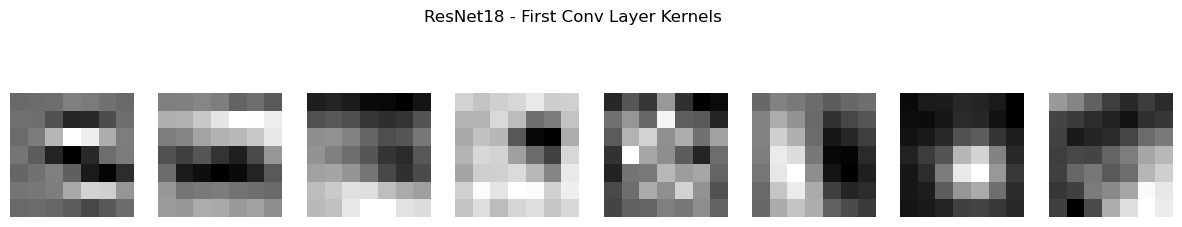

In [30]:
import torch
import torchvision.models as models
import matplotlib.pyplot as plt
import numpy as np

# Загружаем модели
vgg = models.vgg16(weights=models.VGG16_Weights.DEFAULT)
resnet = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

# Извлекаем несколько первых слоев сверток
vgg_kernels = vgg.features[0].weight.data.clone()
resnet_kernels = resnet.conv1.weight.data.clone()

print("VGG first layer shape:", vgg_kernels.shape)      # [64, 3, 3, 3]
print("ResNet first layer shape:", resnet_kernels.shape) # [64, 3, 7, 7]

def normalize_kernel(k):
    k_min, k_max = k.min(), k.max()
    return (k - k_min) / (k_max - k_min)

def show_kernels(weights, title, n=8):
    fig, axes = plt.subplots(1, n, figsize=(15, 3))
    for i in range(n):
        k = weights[i]
        k = normalize_kernel(k)
        # convert (3,H,W) -> (H,W,3)
        k_img = np.transpose(k.numpy(), (1, 2, 0))
        axes[i].imshow(k_img[:, :, 0], cmap = "gray")
        axes[i].axis('off')
    plt.suptitle(title)
    plt.show()

show_kernels(vgg_kernels, "VGG16 - First Conv Layer Kernels")
show_kernels(resnet_kernels, "ResNet18 - First Conv Layer Kernels")

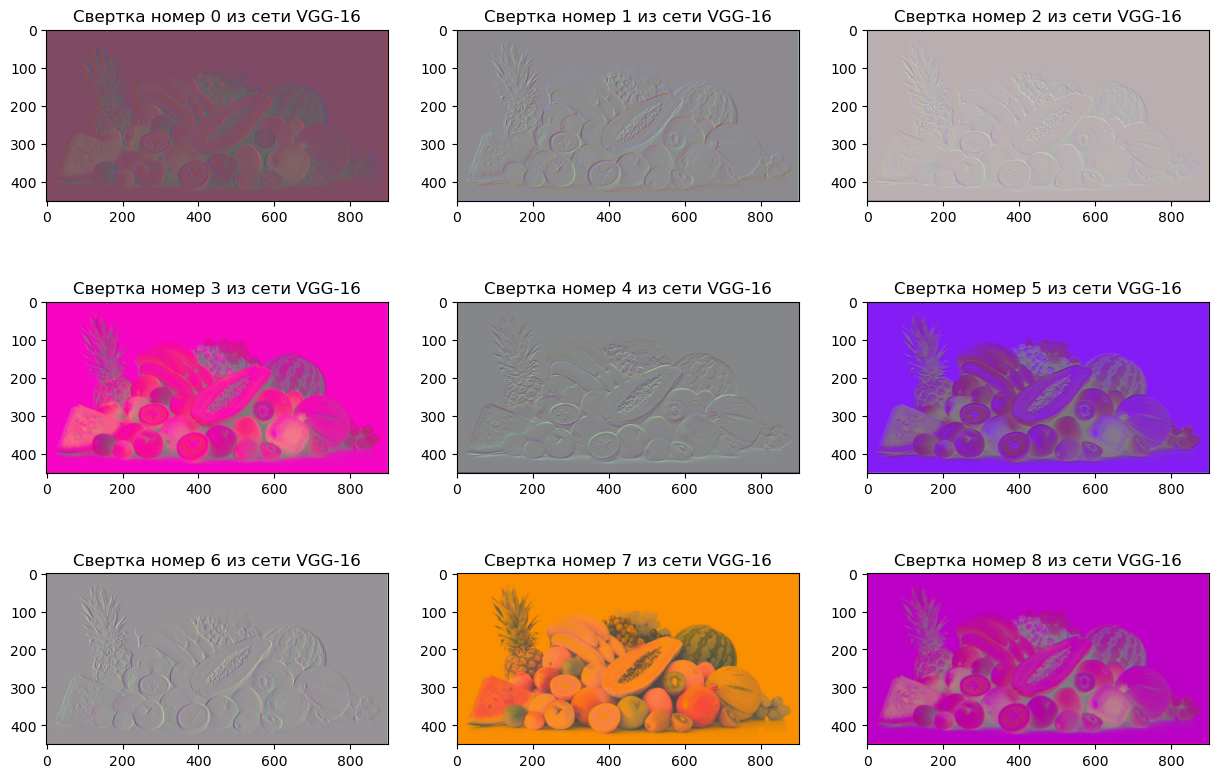

In [31]:
def get_rbg_convolution(img, kernel):
  conv_r = get_convolution(img[:, :, 0], kernel[0])
  conv_g = get_convolution(img[:, :, 1], kernel[1])
  conv_b = get_convolution(img[:, :, 2], kernel[2])
  return normalize_kernel(np.stack([conv_r, conv_g, conv_b]).transpose(1,2,0))

fig, ax = plt.subplots(3, 3, figsize = (15,10))
ax = ax.ravel()
for i in range(9):
  conv_img = get_rbg_convolution(img_rgb, vgg_kernels.numpy()[i])
  ax[i].imshow(conv_img)
  ax[i].set_title(f"Свертка номер {i} из сети VGG-16")

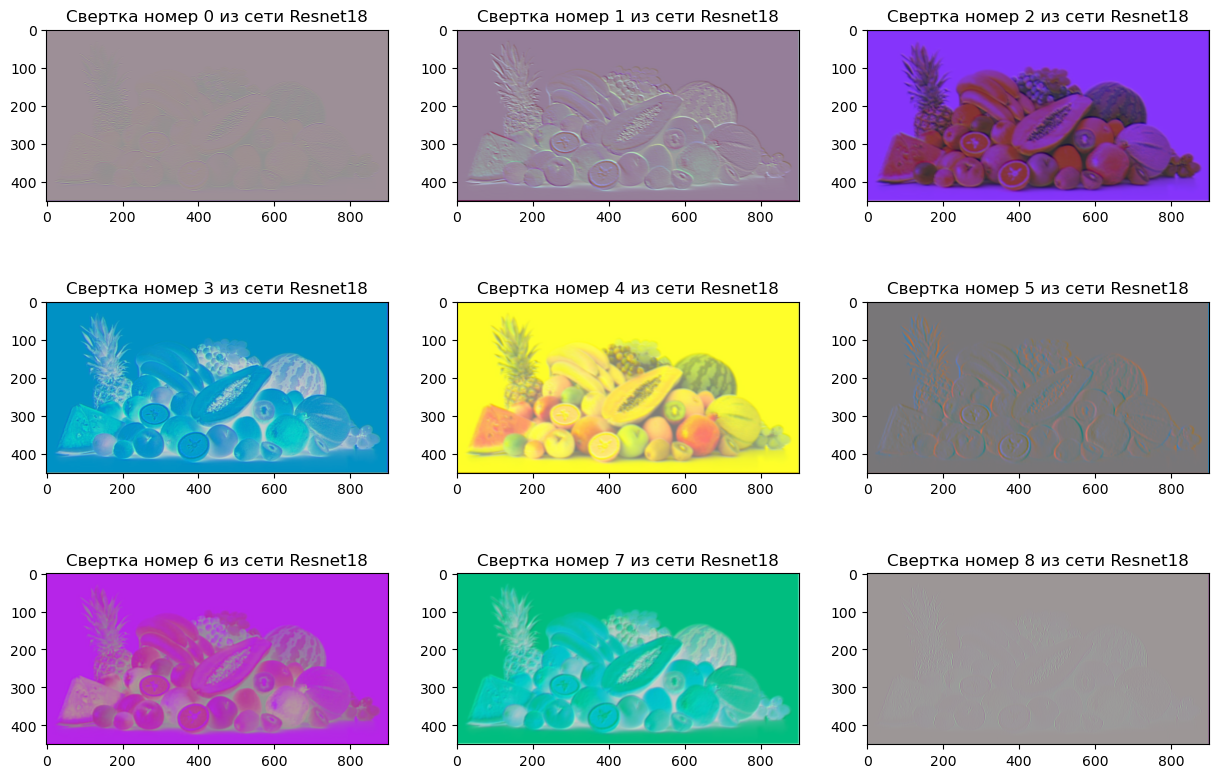

In [32]:
fig, ax = plt.subplots(3, 3, figsize = (15,10))
ax = ax.ravel()
for i in range(9):
  conv_img = get_rbg_convolution(img_rgb, resnet_kernels.numpy()[i])
  ax[i].imshow(conv_img)
  ax[i].set_title(f"Свертка номер {i} из сети Resnet18")

# 3. Обучение CNN для классификации

## 3.1.  Подготовка данных

In [ ]:
import torch
from torch import nn
import torch.nn.functional as F
from torchvision import datasets
from torchvision import transforms
from torch.utils.data import DataLoader

import matplotlib.pyplot as plt
import seaborn as sns

import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
%matplotlib inline

In [ ]:
training_data = datasets.CIFAR10(
    root="data",
    train=True,
    download=True,
    transform=transforms.ToTensor()
)

test_data = datasets.CIFAR10(
    root="data",
    train=False,
    download=True,
    transform=transforms.ToTensor()
)

In [ ]:
print('Размер обучающей выборки:', training_data.data.shape)
print(len(training_data.targets))
print('Размер тестовой выборки:', test_data.data.shape)
print(len(test_data.targets))

Размер обучающей выборки: (50000, 32, 32, 3)
50000
Размер тестовой выборки: (10000, 32, 32, 3)
10000


In [ ]:
labels_dict = {j:i for i, j in training_data.class_to_idx.items()}
labels_dict

{0: 'airplane',
 1: 'automobile',
 2: 'bird',
 3: 'cat',
 4: 'deer',
 5: 'dog',
 6: 'frog',
 7: 'horse',
 8: 'ship',
 9: 'truck'}

truck


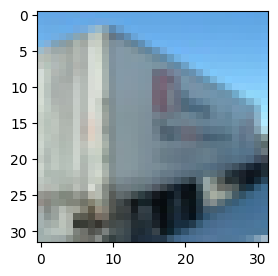

In [ ]:
img, label = training_data[15]
print(labels_dict[label])
figure = plt.figure(figsize = (3,3))
plt.imshow(np.transpose(img, (1,2,0)))
plt.show()

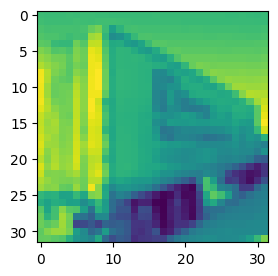

In [ ]:
gray = transforms.Grayscale()
gray_img = gray(img)
figure = plt.figure(figsize = (3,3))
plt.imshow(np.transpose(gray_img, (1,2,0)), cmap = "gray")
plt.show()

In [ ]:
gray_img.size()

torch.Size([1, 32, 32])

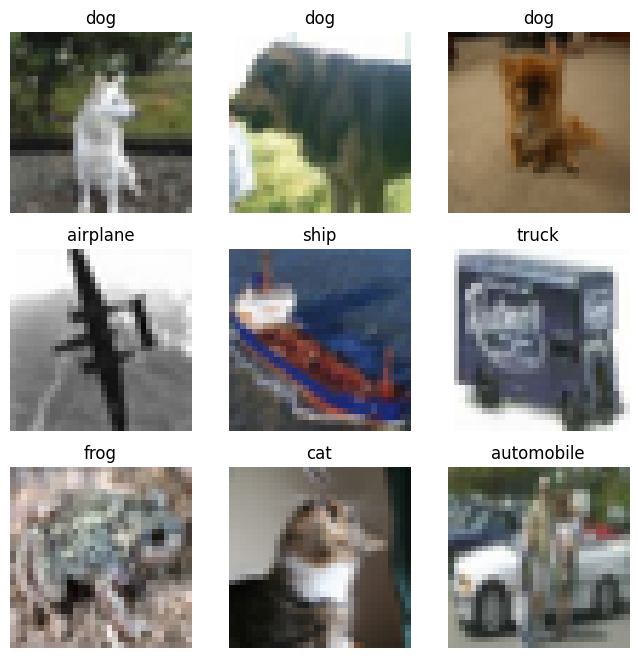

In [ ]:
figure = plt.figure(figsize=(8, 8))
cols, rows = 3, 3
for i in range(1, cols * rows + 1):
    sample_idx = torch.randint(len(training_data), size=(1,)).item()
    img, label = training_data[sample_idx]
    figure.add_subplot(rows, cols, i)
    plt.title(labels_dict[label])
    plt.axis("off")
    plt.imshow(np.transpose(img, (1, 2, 0)))
plt.show()

## 3.2. Загрузка утилит

In [ ]:
learning_rate = 1e-3
batch_size = 64

In [ ]:
train_dataloader = DataLoader(training_data, batch_size=batch_size, shuffle=True)
test_dataloader = DataLoader(test_data, batch_size=batch_size, shuffle=True)

In [ ]:
device = torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else "cpu"
print(f"Using {device} device")

Using cuda device


In [ ]:
def train_loop(dataloader, model, loss_fn, optimizer, device):
    size = len(dataloader.dataset)
    # Set the model to training mode - important for batch normalization and dropout layers
    # Unnecessary in this situation but added for best practices
    model.train()
    for batch, (X, y) in enumerate(dataloader):
        X = X.to(device)
        y = y.to(device)
        # Compute prediction and loss
        pred = model(X)
        loss = loss_fn(pred, y)

        # Backpropagation
        loss.backward()
        optimizer.step()
        optimizer.zero_grad()

        if batch % 100 == 0:
            loss, current = loss.item(), batch * batch_size + len(X)
            print(f"loss: {loss:>7f}  [{current:>5d}/{size:>5d}]")


def test_loop(dataloader, model, loss_fn, device):
    # Set the model to evaluation mode - important for batch normalization and dropout layers
    # Unnecessary in this situation but added for best practices
    model.eval()
    size = len(dataloader.dataset)
    num_batches = len(dataloader)
    test_loss, correct = 0, 0

    # Evaluating the model with torch.no_grad() ensures that no gradients are computed during test mode
    # also serves to reduce unnecessary gradient computations and memory usage for tensors with requires_grad=True
    with torch.no_grad():
        for X, y in dataloader:
            X = X.to(device)
            y = y.to(device)
            pred = model(X)
            test_loss += loss_fn(pred, y).item()
            correct += (pred.argmax(1) == y).type(torch.float).sum().item()

    test_loss /= num_batches
    correct /= size
    print(f"Test Error: \n Accuracy: {(100*correct):>0.1f}%, Avg loss: {test_loss:>8f} \n")

## 3.3. Простая полносвязная нейросеть

In [ ]:
class SimpleNeuralNetwork(nn.Module):
    def __init__(self, n_classes):
        super().__init__()
        self.grayscale = transforms.Grayscale()
        self.flatten = nn.Flatten()
        self.network = nn.Sequential(
            nn.Linear(1*32*32, 512),
            nn.ReLU(),
            nn.Linear(512, 512),
            nn.ReLU(),
            nn.Linear(512, n_classes),
        )

    def forward(self, x):
        x = self.grayscale(x)
        x = self.flatten(x)
        x = self.network(x)
        return x

In [ ]:
simple_nn_model = SimpleNeuralNetwork(n_classes = 10).to(device)
print(simple_nn_model)

SimpleNeuralNetwork(
  (grayscale): Grayscale(num_output_channels=1)
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (network): Sequential(
    (0): Linear(in_features=1024, out_features=512, bias=True)
    (1): ReLU()
    (2): Linear(in_features=512, out_features=512, bias=True)
    (3): ReLU()
    (4): Linear(in_features=512, out_features=10, bias=True)
  )
)


In [ ]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(simple_nn_model.parameters(), lr=learning_rate)

In [ ]:
epochs = 10
for t in range(epochs):
    print(f"Epoch {t+1}\n-------------------------------")
    train_loop(train_dataloader, simple_nn_model, loss_fn, optimizer, device)
    test_loop(test_dataloader, simple_nn_model, loss_fn, device)
print("Done!")

Epoch 1
-------------------------------
loss: 2.301169  [   64/50000]
loss: 1.994931  [ 6464/50000]
loss: 2.052412  [12864/50000]
loss: 1.887740  [19264/50000]
loss: 2.183102  [25664/50000]
loss: 1.960119  [32064/50000]
loss: 2.043390  [38464/50000]
loss: 1.979331  [44864/50000]
Test Error: 
 Accuracy: 30.3%, Avg loss: 1.970809 

Epoch 2
-------------------------------
loss: 2.058042  [   64/50000]
loss: 2.000503  [ 6464/50000]
loss: 2.024368  [12864/50000]
loss: 1.833667  [19264/50000]
loss: 1.743217  [25664/50000]
loss: 2.150601  [32064/50000]
loss: 1.784948  [38464/50000]
loss: 1.849285  [44864/50000]
Test Error: 
 Accuracy: 35.8%, Avg loss: 1.818765 

Epoch 3
-------------------------------
loss: 1.727378  [   64/50000]
loss: 1.802170  [ 6464/50000]
loss: 1.797353  [12864/50000]
loss: 1.806503  [19264/50000]
loss: 1.792099  [25664/50000]
loss: 1.798160  [32064/50000]
loss: 1.884108  [38464/50000]
loss: 1.823818  [44864/50000]
Test Error: 
 Accuracy: 35.3%, Avg loss: 1.802297 

Epoc

ship


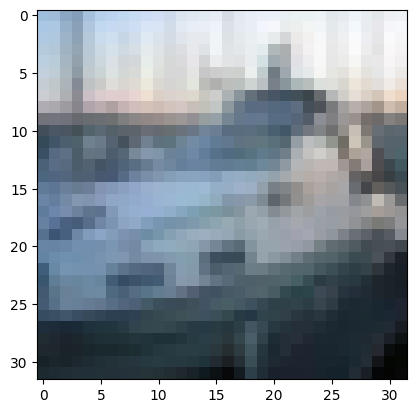

In [ ]:
img, label = test_data[2]
print(labels_dict[label])
plt.imshow(np.transpose(img.cpu().numpy(), (1, 2, 0)))
plt.show()

In [ ]:
logits = simple_nn_model(img.to(device))
pred_probab = nn.Softmax(dim=1)(logits)
y_pred = pred_probab.argmax(1)
print(f"Predicted class: {y_pred}")
print(f"Predicted object: {labels_dict[y_pred.cpu().numpy()[0]]}")

Predicted class: tensor([8], device='cuda:0')
Predicted object: ship


              precision    recall  f1-score   support

    airplane       0.46      0.40      0.43      1000
  automobile       0.52      0.49      0.50      1000
        bird       0.30      0.40      0.34      1000
         cat       0.29      0.16      0.21      1000
        deer       0.33      0.33      0.33      1000
         dog       0.35      0.46      0.40      1000
        frog       0.41      0.45      0.43      1000
       horse       0.57      0.37      0.45      1000
        ship       0.48      0.56      0.52      1000
       truck       0.47      0.51      0.49      1000

    accuracy                           0.41     10000
   macro avg       0.42      0.41      0.41     10000
weighted avg       0.42      0.41      0.41     10000



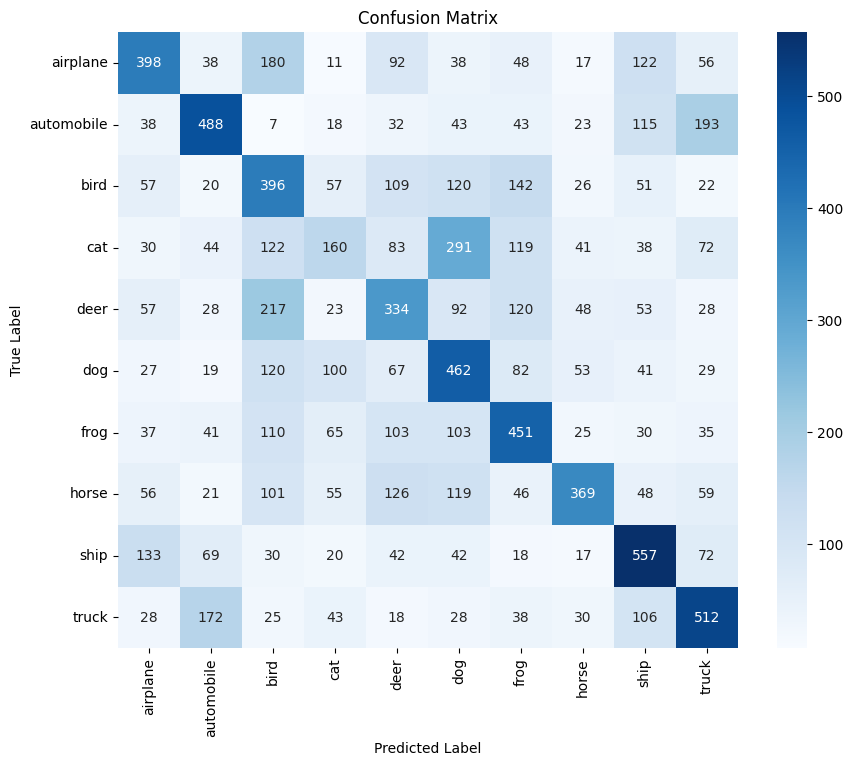

In [ ]:
simple_nn_model.eval()

all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in test_dataloader:
        images, labels = images.to(device), labels.to(device)
        outputs = simple_nn_model(images)
        _, predicted = torch.max(outputs, 1)
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

print(classification_report(all_labels, all_preds, target_names=labels_dict.values()))

cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(10,8))
sns.heatmap(cm, annot=True, fmt="d", cmap=plt.cm.Blues, xticklabels=labels_dict.values(), yticklabels=labels_dict.values())
plt.xlabel('Predicted Label')  # x-axis label
plt.ylabel('True Label')       # y-axis label
plt.title('Confusion Matrix')  # Title of the plot
plt.show()

## 3.4. Convolutional Neural Network

Типичная CNN архитектура состоит из :

*   Сверточный слой (Convolutional Layer): Применяют операцию свертки к входящему слою для выделения признаков.
*   Активационый слой (Activation Layer): Добавляет нелинейность к модели (обычно  ReLU).
*   Слой объединения (Pooling Layer): Производят снижение размерности.
*   Полносвязные слои (Fully Connected Layers): После нескольких сверточных и пулинговых слоев.





In [ ]:
class BasicCNN(nn.Module):
    def __init__(self, n_classes):
        super(BasicCNN, self).__init__()
        self.network = nn.Sequential(
            # Input 3x32x32
            nn.Conv2d(3, 32, kernel_size = 3, padding = 1), # Output 32x32x32
            nn.ReLU(),
            nn.MaxPool2d(2, 2), # 32x16x16
            nn.Flatten(),
            nn.Linear(8192, 1024),
            nn.ReLU(),
            nn.Linear(1024, 512),
            nn.ReLU(),
            nn.Linear(512, n_classes)
        )

    def forward(self, x):
        return self.network(x)

In [ ]:
basic_cnn_model = BasicCNN(n_classes = 10).to(device)

In [ ]:
optimizer = torch.optim.Adam(basic_cnn_model.parameters(), lr=0.001)
criterion = nn.CrossEntropyLoss()

In [ ]:
epochs = 10
for t in range(epochs):
    print(f"Epoch {t+1}\n-------------------------------")
    train_loop(train_dataloader, basic_cnn_model, loss_fn, optimizer, device)
    #test_loop(test_dataloader, model, loss_fn, device)
print("Done!")

Epoch 1
-------------------------------
loss: 2.310254  [   64/50000]
loss: 1.800611  [ 6464/50000]
loss: 1.675129  [12864/50000]
loss: 1.422611  [19264/50000]
loss: 1.313960  [25664/50000]
loss: 1.504433  [32064/50000]
loss: 1.207103  [38464/50000]
loss: 1.352885  [44864/50000]
Epoch 2
-------------------------------
loss: 1.186562  [   64/50000]
loss: 1.326650  [ 6464/50000]
loss: 0.982341  [12864/50000]
loss: 1.141155  [19264/50000]
loss: 1.042176  [25664/50000]
loss: 1.143966  [32064/50000]
loss: 1.063427  [38464/50000]
loss: 1.060918  [44864/50000]
Epoch 3
-------------------------------
loss: 0.969215  [   64/50000]
loss: 0.978857  [ 6464/50000]
loss: 0.904047  [12864/50000]
loss: 0.866526  [19264/50000]
loss: 1.019388  [25664/50000]
loss: 0.778871  [32064/50000]
loss: 0.781373  [38464/50000]
loss: 1.002470  [44864/50000]
Epoch 4
-------------------------------
loss: 0.840963  [   64/50000]
loss: 0.863183  [ 6464/50000]
loss: 0.969674  [12864/50000]
loss: 0.846954  [19264/50000]


              precision    recall  f1-score   support

    airplane       0.63      0.78      0.69      1000
  automobile       0.79      0.80      0.79      1000
        bird       0.56      0.54      0.55      1000
         cat       0.49      0.49      0.49      1000
        deer       0.63      0.56      0.60      1000
         dog       0.58      0.53      0.55      1000
        frog       0.72      0.71      0.72      1000
       horse       0.75      0.70      0.73      1000
        ship       0.74      0.83      0.78      1000
       truck       0.77      0.72      0.74      1000

    accuracy                           0.67     10000
   macro avg       0.67      0.67      0.66     10000
weighted avg       0.67      0.67      0.66     10000



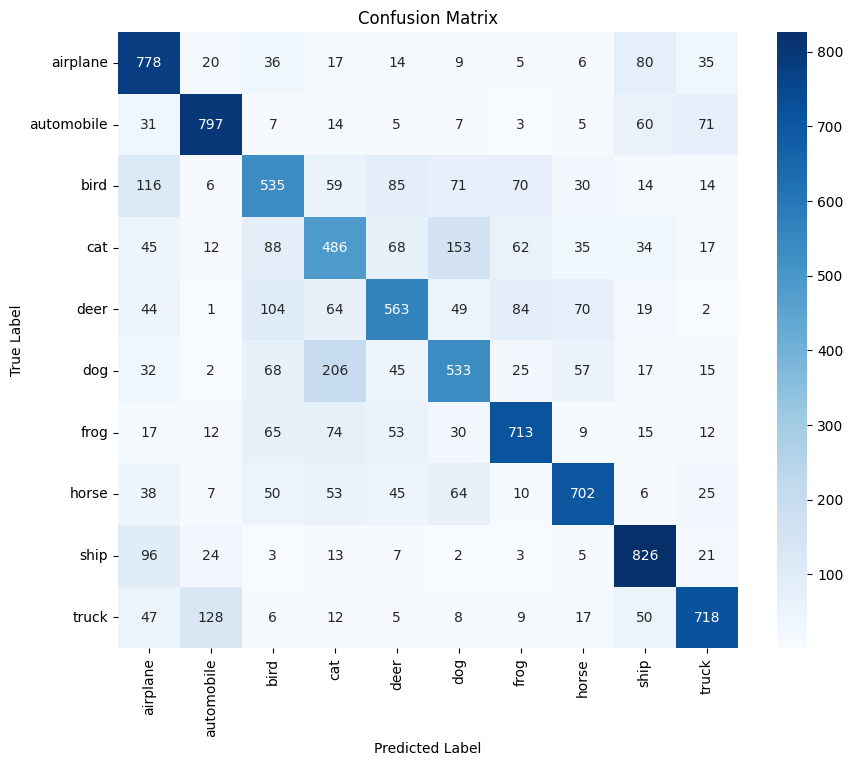

In [ ]:
basic_cnn_model.eval()

all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in test_dataloader:
        images, labels = images.to(device), labels.to(device)
        outputs = basic_cnn_model(images)
        _, predicted = torch.max(outputs, 1)
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

print(classification_report(all_labels, all_preds, target_names=labels_dict.values()))

cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(10,8))
sns.heatmap(cm, annot=True, fmt="d", cmap=plt.cm.Blues, xticklabels=labels_dict.values(), yticklabels=labels_dict.values())
plt.xlabel('Predicted Label')  # x-axis label
plt.ylabel('True Label')       # y-axis label
plt.title('Confusion Matrix')  # Title of the plot
plt.show()

## 3.5. CNN посложнее

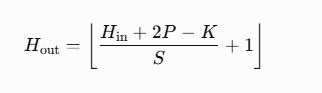

- K - размер ядра
- P - padding
- S - stride

In [ ]:
class CNNModel(nn.Module):
    def __init__(self, n_classes):
        super(CNNModel, self).__init__()
        self.flatten = nn.Flatten()
        self.features = nn.Sequential(
            nn.Conv2d(3, 64, kernel_size=3, padding=2), # (32 + 2*2 - 3)/1 + 1 = 34 => 64 x 34 x 34
            nn.ReLU(), # 64 x 34 x 34
            nn.MaxPool2d(kernel_size=3, stride=2), # FLOOR((34 + 2*0 - 3)/2 + 1) = 16 => 64 x 16 x 16 
            nn.Conv2d(64, 128, kernel_size=5, padding=2), # (16 + 2*2 - 5)/1 + 1 = 16 => = 128 x 16 x 16
            nn.ReLU(), # 128 x 16 x 16
            nn.MaxPool2d(kernel_size=3, stride=2), # 128 x 7 x 7
            nn.Conv2d(128, 256, kernel_size=3, padding=1), # 256 x 7 x 7
            nn.ReLU(), # 256 x 7 x 7
            nn.Conv2d(256, 256, kernel_size=3, padding=1), # 256 x 7 x 7
            nn.ReLU(), # 256 x 7 x 7
            nn.MaxPool2d(kernel_size=3, stride=2) # 256 x 3 x 3
        )
        self.avgpool = nn.AdaptiveAvgPool2d((6, 6)) # 256 x 6 x 6
        self.classifier = nn.Sequential(
            nn.Dropout(),
            nn.Linear(256 * 6 * 6, 4096), 
            nn.ReLU(),
            nn.Dropout(),
            nn.Linear(4096, 4096),
            nn.ReLU(),
            nn.Linear(4096, n_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.avgpool(x)
        x = self.flatten(x)
        x = self.classifier(x)
        return x

In [ ]:
cnn_model = CNNModel(n_classes = 10).to(device)
optimizer = torch.optim.Adam(cnn_model.parameters(), lr=0.001)
criterion = nn.CrossEntropyLoss()

In [ ]:
epochs = 10
for t in range(epochs):
    print(f"Epoch {t+1}\n-------------------------------")
    train_loop(train_dataloader, cnn_model, loss_fn, optimizer, device)
    #test_loop(test_dataloader, model, loss_fn, device)
print("Done!")

Epoch 1
-------------------------------
loss: 2.301763  [   64/50000]
loss: 2.084960  [ 6464/50000]
loss: 1.975174  [12864/50000]
loss: 1.840579  [19264/50000]
loss: 1.663818  [25664/50000]
loss: 1.746979  [32064/50000]
loss: 1.473274  [38464/50000]
loss: 1.344326  [44864/50000]
Epoch 2
-------------------------------
loss: 1.335615  [   64/50000]
loss: 1.474442  [ 6464/50000]
loss: 1.388180  [12864/50000]
loss: 1.324876  [19264/50000]
loss: 1.235525  [25664/50000]
loss: 1.409197  [32064/50000]
loss: 1.373796  [38464/50000]
loss: 1.377056  [44864/50000]
Epoch 3
-------------------------------
loss: 1.103923  [   64/50000]
loss: 1.536783  [ 6464/50000]
loss: 1.322373  [12864/50000]
loss: 1.143800  [19264/50000]
loss: 1.474544  [25664/50000]
loss: 1.137449  [32064/50000]
loss: 1.154598  [38464/50000]
loss: 1.214695  [44864/50000]
Epoch 4
-------------------------------
loss: 1.126995  [   64/50000]
loss: 1.146266  [ 6464/50000]
loss: 1.160368  [12864/50000]
loss: 1.314867  [19264/50000]


              precision    recall  f1-score   support

    airplane       0.75      0.67      0.71      1000
  automobile       0.80      0.84      0.82      1000
        bird       0.55      0.54      0.54      1000
         cat       0.44      0.37      0.40      1000
        deer       0.62      0.62      0.62      1000
         dog       0.48      0.68      0.56      1000
        frog       0.72      0.76      0.74      1000
       horse       0.75      0.69      0.72      1000
        ship       0.83      0.77      0.80      1000
       truck       0.82      0.73      0.77      1000

    accuracy                           0.67     10000
   macro avg       0.67      0.67      0.67     10000
weighted avg       0.67      0.67      0.67     10000



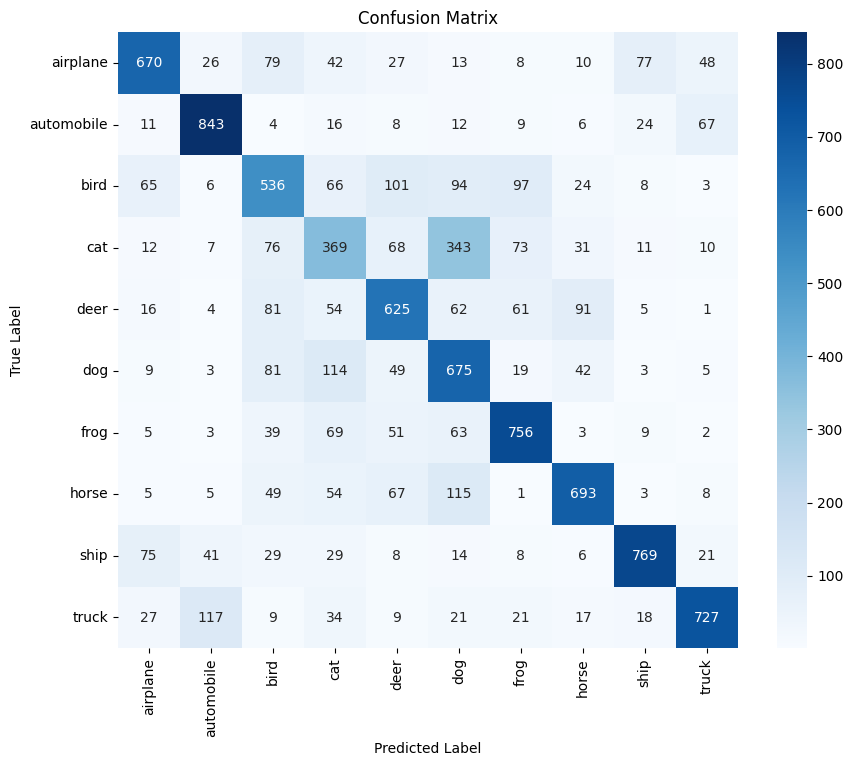

In [ ]:
cnn_model.eval()

all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in test_dataloader:
        images, labels = images.to(device), labels.to(device)
        outputs = cnn_model(images)
        _, predicted = torch.max(outputs, 1)
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

print(classification_report(all_labels, all_preds, target_names=labels_dict.values()))

cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(10,8))
sns.heatmap(cm, annot=True, fmt="d", cmap=plt.cm.Blues, xticklabels=labels_dict.values(), yticklabels=labels_dict.values())
plt.xlabel('Predicted Label')  # x-axis label
plt.ylabel('True Label')       # y-axis label
plt.title('Confusion Matrix')  # Title of the plot
plt.show()